# Chapitre 2 - Cours 3 : files d'attente, débit et temps de réponse

Le cours 2 a montré que la queue de la distribution des temps de réponse est surtout faite
d'**attente**. Ce notebook explique d'où vient cette attente avec un peu de théorie des
files d'attente, que le livre évoque sans la développer : pourquoi le temps de réponse
explose quand le débit approche de la capacité, ce que dit la loi de Little, comment
une requête lente bloque celles qui la suivent, pourquoi mutualiser les serveurs aide,
et comment ne pas se tromper en mesurant sous charge. Il approfondit la section
*Describing Performance* (relation entre débit et temps de réponse, *Latency and Response Time* pour le blocage en tête de file, encadré *When an Overloaded System Won't Recover*).

**Plan.**

1. La courbe en crosse de hockey : temps de réponse en fonction du débit.
2. Pourquoi on attend : hasard des arrivées et loi de Little.
3. Variabilité du service et blocage en tête de file.
4. Plusieurs serveurs : mutualiser la file et dimensionner.
5. Mesurer sous charge : boucle ouverte ou boucle fermée.
6. Quand un système surchargé ne se rétablit pas : tempêtes de relances et panne métastable.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)

## 1. La courbe en crosse de hockey (section *Describing Performance*)

**Le modèle.** Un serveur à un cœur traite les requêtes une par une, dans l'ordre
d'arrivée (FIFO). Les requêtes arrivent au hasard, au rythme moyen de $\lambda$ par
seconde (processus de Poisson : instants d'arrivée indépendants) ; chacune demande un
temps de service aléatoire de moyenne $1/\mu$ (ici exponentiel, de moyenne 10 ms, soit
une capacité $\mu = 100$ requêtes par seconde). C'est la file **M/M/1** (Markov pour les
arrivées, Markov pour le service, 1 serveur). Le rapport $\rho = \lambda / \mu$ est le
**taux d'occupation** du serveur.

**Le résultat.** Le temps de réponse moyen vaut
$$W = \frac{1}{\mu - \lambda} = \frac{1/\mu}{1 - \rho},$$
et il est même distribué selon une loi exponentielle de paramètre $\mu - \lambda$, d'où
un p99 de $\ln(100)/(\mu - \lambda)$. Le facteur $1/(1-\rho)$ est la clé : à 50 %
d'occupation, on attend autant qu'on est servi ; à 90 %, le temps de réponse est
multiplié par 10 ; à 99 %, par 100. Vérifions par simulation (`rq.simulate_fifo`).

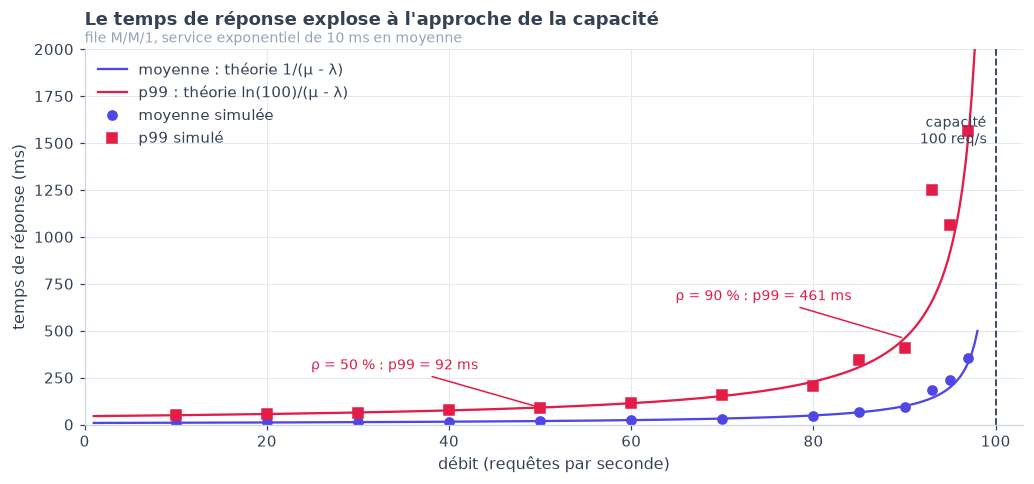

,rho,moyenne,theo_moy,p99,theo_p99
0,0.10,11.1,11.1,50.6,51.2
1,0.20,12.5,12.5,57.3,57.6
2,0.30,14.1,14.3,64.2,65.8
3,0.40,16.6,16.7,77.7,76.8
4,0.50,19.8,20.0,91.8,92.1
5,0.60,25.1,25.0,117.2,115.1
6,0.70,33.2,33.3,156.3,153.5
7,0.80,47.2,50.0,204.3,230.3
8,0.85,68.3,66.7,346.0,307.0
9,0.90,93.5,100.0,409.3,460.5


In [2]:
mu = 100.0                        # requêtes par seconde
rhos = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.93, 0.95, 0.97])
rows = []
for i, rho in enumerate(rhos):
    n = 100_000
    arr = rq.poisson_arrivals(rho * mu, n, seed=i)
    svc = np.random.default_rng(100 + i).exponential(1 / mu, n)
    st, en = rq.simulate_fifo(arr, svc)
    resp = (en - arr)[n // 10:] * 1e3                     # on écarte le démarrage à vide
    rows.append(dict(rho=rho, debit=rho * mu, moyenne=resp.mean(), p99=np.percentile(resp, 99),
                     theo_moy=rq.mm1(rho * mu, mu)["W"] * 1e3,
                     theo_p99=rq.mm1_response_quantile(rho * mu, mu, 0.99) * 1e3))
M = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9.5, 4.5))
lam = np.linspace(1, 98, 300)
ax.plot(lam, 1e3 / (mu - lam), color=INDIGO, lw=1.5, label="moyenne : théorie 1/(µ - λ)")
ax.plot(lam, math.log(100) * 1e3 / (mu - lam), color=ROSE, lw=1.5, label="p99 : théorie ln(100)/(µ - λ)")
ax.plot(M.debit, M.moyenne, "o", color=INDIGO, label="moyenne simulée")
ax.plot(M.debit, M.p99, "s", color=ROSE, label="p99 simulé")
ax.axvline(mu, color=SLATE, ls="--", lw=1.2)
ax.text(mu - 1, 1500, "capacité\n100 req/s", ha="right", color=SLATE, fontsize=9)
for r in [0.5, 0.9]:
    v = math.log(100) * 1e3 / (mu - r * mu)
    ax.annotate(f"ρ = {r * 100:.0f} % : p99 = {v:.0f} ms", (r * mu, v), (-150, 25), textcoords="offset points",
                fontsize=9, color=ROSE, arrowprops=dict(arrowstyle="-", color=ROSE))
ax.set_ylim(0, 2000); ax.set_xlim(0, 103)
ax.set_xlabel("débit (requêtes par seconde)"); ax.set_ylabel("temps de réponse (ms)")
ax.set_title("Le temps de réponse explose à l'approche de la capacité")
subtitle(ax, "file M/M/1, service exponentiel de 10 ms en moyenne")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
M[["rho", "moyenne", "theo_moy", "p99", "theo_p99"]].round({"rho": 2, "moyenne": 1, "theo_moy": 1, "p99": 1, "theo_p99": 1})

La simulation suit la théorie, avec un peu de bruit aux fortes charges (les files très
chargées ont une forte inertie et convergent lentement). La forme en **crosse de hockey**
est universelle : quel que soit le système, le temps de réponse reste plat tant que
l'occupation est faible, puis monte en flèche. Deux conséquences pratiques :

- on ne fait pas tourner un service interactif à 95 % d'occupation : la **marge** de
  capacité est ce qui garde la queue de distribution courte ;
- à forte charge, une petite hausse du trafic (10 % de plus) peut doubler le temps de
  réponse : le système devient **fragile**.

> **À retenir.** Dans une file d'attente, le temps de réponse moyen est multiplié par
> $1/(1-\rho)$, où $\rho$ est le taux d'occupation : il explose quand le débit approche
> de la capacité. La capacité utile d'un service interactif est bien inférieure à sa
> capacité brute.

## 2. Pourquoi on attend : hasard des arrivées et loi de Little

Pourquoi attendre si le serveur est libre la moitié du temps ? Parce que les arrivées
sont **irrégulières** : parfois trois requêtes arrivent coup sur coup, et la deuxième et
la troisième attendent. Si les requêtes arrivaient à intervalles parfaitement réguliers
avec un service constant, il n'y aurait **aucune** attente jusqu'à 100 % d'occupation.
Comparons, à 80 % d'occupation, trois niveaux de hasard (pour les deux derniers, la
formule de Pollaczek-Khinchine de la section 3 donne l'attente moyenne exacte).

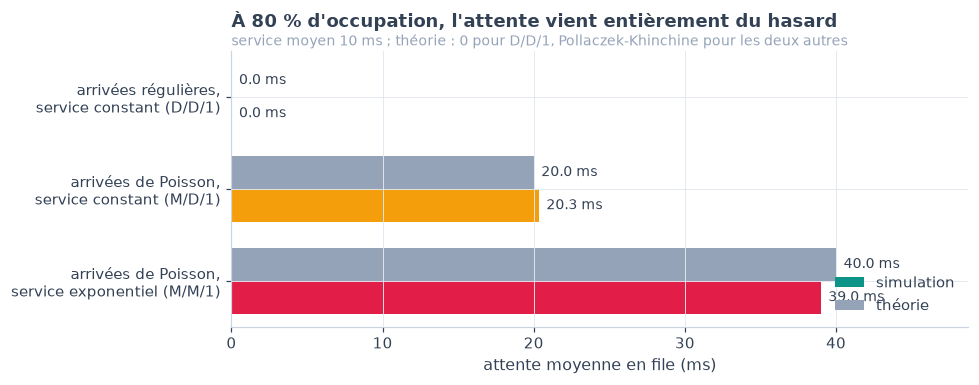

In [3]:
rho, n = 0.8, 200_000
cas = {}
gen = np.random.default_rng(1)
cas["arrivées régulières,\nservice constant (D/D/1)"] = (np.arange(n) / (rho * mu), np.full(n, 1 / mu))
cas["arrivées de Poisson,\nservice constant (M/D/1)"] = (rq.poisson_arrivals(rho * mu, n, seed=2), np.full(n, 1 / mu))
cas["arrivées de Poisson,\nservice exponentiel (M/M/1)"] = (rq.poisson_arrivals(rho * mu, n, seed=3), gen.exponential(1 / mu, n))
theo = [0.0, rq.mg1_wait(rho * mu, 1 / mu, 0.0) * 1e3, rq.mg1_wait(rho * mu, 1 / mu, 1.0) * 1e3]
att = []
for nom, (a, s) in cas.items():
    st, en = rq.simulate_fifo(a, s)
    att.append((st - a).mean() * 1e3)
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(3)
ax.barh(y + 0.18, att, height=0.36, color=[TEAL, AMBER, ROSE], label="simulation")
ax.barh(y - 0.18, theo, height=0.36, color=GRAY, label="théorie")
for i, (a_, t_) in enumerate(zip(att, theo)):
    ax.text(a_ + 0.5, i + 0.18, f"{a_:.1f} ms", va="center", fontsize=9)
    ax.text(t_ + 0.5, i - 0.18, f"{t_:.1f} ms", va="center", fontsize=9, color=SLATE)
ax.set_yticks(y); ax.set_yticklabels(list(cas)); ax.invert_yaxis()
ax.set_xlabel("attente moyenne en file (ms)"); ax.set_xlim(0, max(att) * 1.25)
ax.set_title("À 80 % d'occupation, l'attente vient entièrement du hasard")
subtitle(ax, "service moyen 10 ms ; théorie : 0 pour D/D/1, Pollaczek-Khinchine pour les deux autres")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Le hasard des arrivées seul (service constant) donne déjà 20 ms d'attente moyenne, deux
fois le temps de service ; un service variable double encore la mise.

**La loi de Little.** C'est le résultat le plus général de la théorie des files, valable
pour presque tout système stable (quelle que soit la discipline, la distribution des
arrivées ou du service) :
$$L = \lambda \, W,$$
où $L$ est le nombre moyen de requêtes présentes dans le système, $\lambda$ le débit et
$W$ le temps moyen passé dans le système. *Intuition* : chaque requête « paie » une
unité de présence par seconde passée dans le système ; sur une durée $T$, l'aire sous la
courbe du nombre de requêtes présentes vaut à la fois $L\,T$ et la somme des temps de
séjour, soit $(\lambda T)\,W$.

C'est un outil de dimensionnement redoutable : un service qui reçoit 2 000 requêtes par
seconde avec un temps de réponse moyen de 50 ms a en permanence $2000 \times 0{,}05 = 100$
requêtes en cours, donc au moins 100 connexions, fils d'exécution ou emplacements
mémoire. Vérifions-la sur la simulation M/M/1, en traçant aussi le nombre de requêtes
présentes au cours du temps.

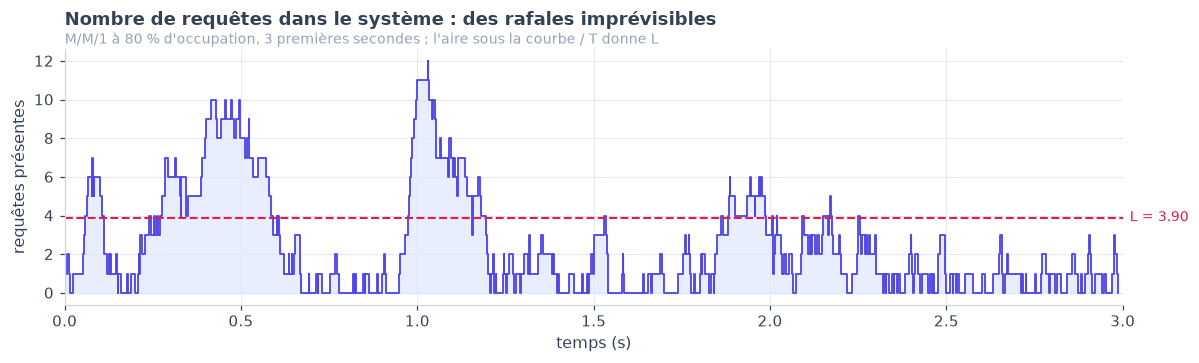

,L mesuré (aire / T),λ mesuré (req/s),W mesuré (s),λ × W,théorie ρ/(1-ρ)
0,3.9,79.79,0.05,3.9,4.0


In [4]:
a, s = cas["arrivées de Poisson,\nservice exponentiel (M/M/1)"]
st, en = rq.simulate_fifo(a, s)
T = en.max()
events = np.concatenate([np.c_[a, np.ones(n)], np.c_[en, -np.ones(n)]])
events = events[np.argsort(events[:, 0], kind="stable")]
N_t = np.cumsum(events[:, 1])
aire = np.sum(N_t[:-1] * np.diff(events[:, 0]))
L_mesure = aire / T
lam_mesure = n / T
W_mesure = (en - a).mean()

fig, ax = plt.subplots(figsize=(11, 3.4))
mask = events[:, 0] < 3
ax.step(events[mask, 0], N_t[mask], where="post", color=INDIGO, lw=1.2)
ax.fill_between(events[mask, 0], N_t[mask], step="post", color=LIGHT[INDIGO], alpha=0.7)
ax.axhline(L_mesure, color=ROSE, ls="--", lw=1.4)
ax.text(3.02, L_mesure, f"L = {L_mesure:.2f}", color=ROSE, va="center", fontsize=9)
ax.set_xlim(0, 3); ax.set_xlabel("temps (s)"); ax.set_ylabel("requêtes présentes")
ax.set_title("Nombre de requêtes dans le système : des rafales imprévisibles")
subtitle(ax, "M/M/1 à 80 % d'occupation, 3 premières secondes ; l'aire sous la courbe / T donne L")
plt.tight_layout(); plt.show()
pd.DataFrame({"L mesuré (aire / T)": [L_mesure], "λ mesuré (req/s)": [lam_mesure], "W mesuré (s)": [W_mesure],
              "λ × W": [lam_mesure * W_mesure], "théorie ρ/(1-ρ)": [rho / (1 - rho)]}).round(3)

$\lambda W$ et l'aire moyenne coïncident (c'est une identité comptable, pas une
approximation), et tous deux sont proches de la valeur théorique $\rho/(1-\rho) = 4$.

> **À retenir.** L'attente naît de l'irrégularité des arrivées et des services, pas d'un
> manque de capacité moyenne. La loi de Little $L = \lambda W$ relie débit, temps de
> réponse et nombre de requêtes en cours : elle sert à dimensionner connexions, fils
> d'exécution et mémoire.

## 3. Variabilité du service et blocage en tête de file (section *Latency and Response Time*)

Pour un serveur unique, la **formule de Pollaczek-Khinchine** donne l'attente moyenne
pour n'importe quelle distribution du temps de service $S$ :
$$W_q = \frac{\lambda\, \mathbb{E}[S^2]}{2(1-\rho)} = \frac{\rho}{1-\rho}\cdot\frac{1 + c_S^2}{2}\cdot\mathbb{E}[S],$$
où $c_S^2 = \mathrm{Var}(S)/\mathbb{E}[S]^2$ est le carré du coefficient de variation.
À charge égale, l'attente est proportionnelle à $1 + c_S^2$ : **la variabilité des
temps de service coûte aussi cher que la charge**. Un service où 1 % des requêtes sont
100 fois plus longues que les autres a un $c_S^2$ d'environ 25 (calcul : avec un service
rapide constant $a$, $\mathbb{E}[S] \approx 1{,}99a$ et $\mathbb{E}[S^2] \approx 101a^2$),
soit une attente 13 fois supérieure au cas exponentiel ($c_S^2 = 1$).

C'est le **blocage en tête de file** (head-of-line blocking) du livre : un serveur ne
traite qu'un petit nombre de requêtes en parallèle (son nombre de cœurs), et il suffit
de quelques requêtes lentes pour retenir toutes celles qui suivent, même si elles sont
rapides. Le diagramme montre trois requêtes de 1 ms coincées derrière une requête de
40 ms.

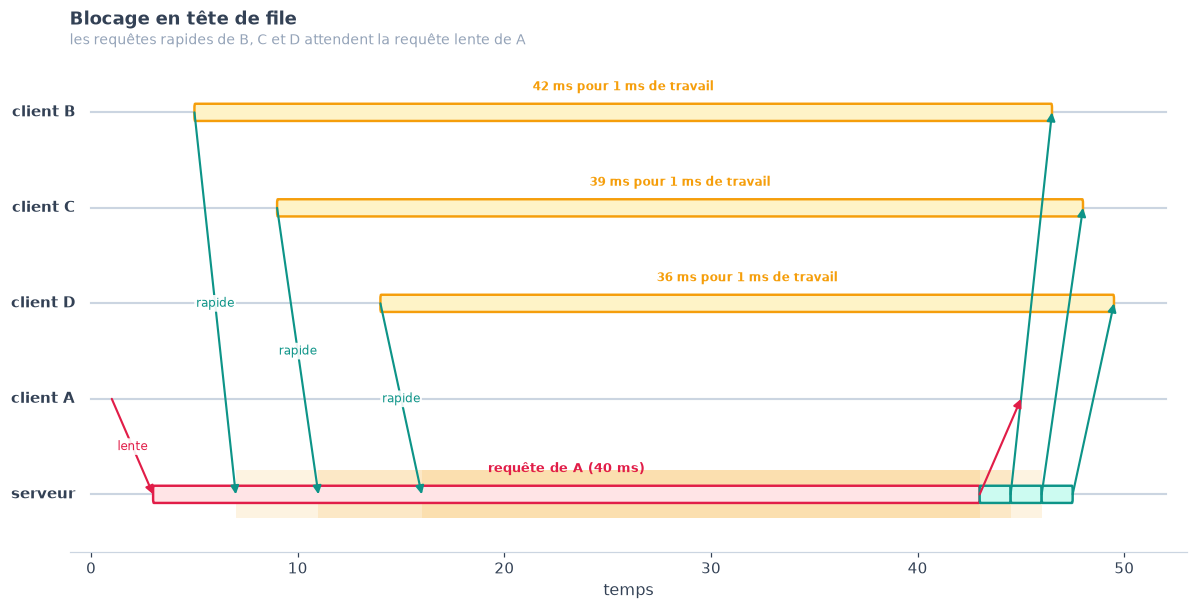

In [5]:
st_ = SpaceTime(["client B", "client C", "client D", "client A", "serveur"], t_max=52, width=11,
                title="Blocage en tête de file",
                subtitle="les requêtes rapides de B, C et D attendent la requête lente de A")
st_.msg("client A", 1, "serveur", 3, "lente", color=ROSE)
st_.op("serveur", 3, 43, "requête de A (40 ms)", color=ROSE)
for i, (c, t0) in enumerate([("client B", 5), ("client C", 9), ("client D", 14)]):
    t_arr = t0 + 2
    t_fin = 43 + (i + 1) * 1.5
    st_.msg(c, t0, "serveur", t_arr, "rapide", color=TEAL)
    st_.span("serveur", t_arr, 43 + i * 1.5, "", color=AMBER, alpha=0.12)
    st_.op("serveur", 43 + i * 1.5, t_fin, "", color=TEAL)
    st_.msg("serveur", t_fin, c, t_fin + 2, "", color=TEAL)
    st_.op(c, t0, t_fin + 2, f"{t_fin + 2 - t0:.0f} ms pour 1 ms de travail", color=AMBER, fontsize=8)
st_.msg("serveur", 43, "client A", 45, "", color=ROSE)
st_.show()

Vérifions la formule et mesurons le préjudice pour les requêtes rapides : à 60 %
d'occupation, des requêtes rapides (service 5 ms, exponentiel) sont mélangées à une
fraction $f$ de requêtes lentes (500 ms) ; la charge totale reste fixée.

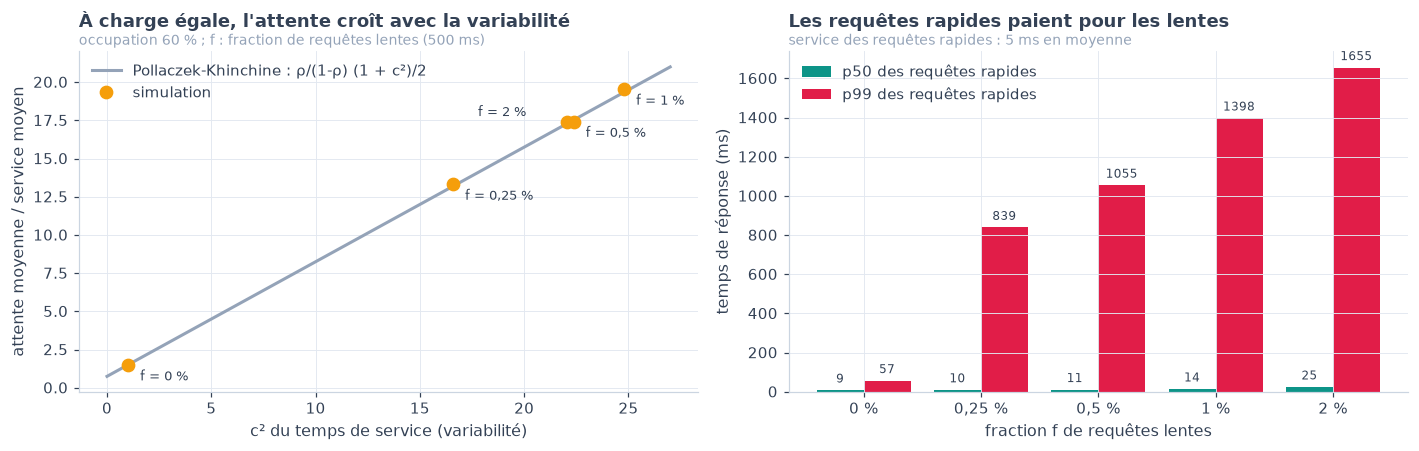

,f,scv,service_moyen,attente_sim,attente_PK,rapides_p50,rapides_p99
0,0.0,1.0,5.0,7.4,7.5,8.6,56.7
1,0.2,16.6,6.3,83.5,82.7,10.1,839.0
2,0.5,22.4,7.5,130.2,131.0,11.4,1054.6
3,1.0,24.8,9.9,192.5,190.6,14.4,1397.5
4,2.0,22.0,14.6,253.1,251.5,24.6,1655.1


In [6]:
rho, n = 0.6, 300_000
rows = []
for f in [0.0, 0.0025, 0.005, 0.01, 0.02]:
    g = np.random.default_rng(int(f * 1e4))
    slow = g.random(n) < f
    svc = np.where(slow, 0.5, g.exponential(0.005, n))
    lam_ = rho / svc.mean()
    arr = rq.poisson_arrivals(lam_, n, seed=7)
    st, en = rq.simulate_fifo(arr, svc)
    resp = (en - arr) * 1e3
    scv = svc.var() / svc.mean() ** 2
    rows.append(dict(f=f * 100, scv=scv, service_moyen=svc.mean() * 1e3, attente_sim=(st - arr).mean() * 1e3,
                     attente_PK=rq.mg1_wait(lam_, svc.mean(), scv) * 1e3,
                     rapides_p50=np.percentile(resp[~slow], 50), rapides_p99=np.percentile(resp[~slow], 99)))
B = pd.DataFrame(rows)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
c2 = np.linspace(0, 27, 50)
ax.plot(c2, rho / (1 - rho) * (1 + c2) / 2, "-", color=GRAY, lw=2, label="Pollaczek-Khinchine : ρ/(1-ρ) (1 + c²)/2")
ax.plot(B.scv, B.attente_sim / B.service_moyen, "o", color=AMBER, ms=8, label="simulation")
for _, r in B.iterrows():
    ax.annotate(f"f = {r.f:g} %".replace(".", ","), (r.scv, r.attente_sim / r.service_moyen),
                (-58, 4) if r.f == 2 else (8, -10),
                textcoords="offset points", fontsize=8.5)
ax.set_xlabel("c² du temps de service (variabilité)"); ax.set_ylabel("attente moyenne / service moyen")
ax.set_title("À charge égale, l'attente croît avec la variabilité")
subtitle(ax, "occupation 60 % ; f : fraction de requêtes lentes (500 ms)")
ax.legend(loc="upper left")
x_ = np.arange(len(B))
ax2.bar(x_ - 0.2, B.rapides_p50, width=0.4, color=TEAL, label="p50 des requêtes rapides")
ax2.bar(x_ + 0.2, B.rapides_p99, width=0.4, color=ROSE, label="p99 des requêtes rapides")
annotate_bars(ax2, "{:.0f}", fontsize=8)
ax2.set_xticks(x_); ax2.set_xticklabels([f"{v:g} %".replace(".", ",") for v in B.f])
ax2.set_xlabel("fraction f de requêtes lentes"); ax2.set_ylabel("temps de réponse (ms)")
ax2.set_title("Les requêtes rapides paient pour les lentes")
subtitle(ax2, "service des requêtes rapides : 5 ms en moyenne")
ax2.legend(loc="upper left")
plt.tight_layout(); plt.show()
B.round(1)

Exprimée en unités de temps de service moyen, l'attente simulée tombe exactement sur la
droite de Pollaczek-Khinchine. (Remarquez que $c_S^2$ n'est pas monotone en $f$ : il est
maximal vers 1 %, au-delà les requêtes lentes deviennent moins « exceptionnelles ».) En
millisecondes, l'attente croît toujours avec $f$ car le service moyen augmente aussi.
Surtout, avec seulement 1 % de
requêtes lentes, le p99 des requêtes **rapides** passe d'une soixantaine de
millisecondes à plus d'une seconde : elles ne coûtent que 5 ms de travail mais subissent
le blocage. Remèdes classiques : isoler les requêtes coûteuses dans une
file (ou un pool de serveurs) à part, découper les gros traitements, ou limiter la
durée d'une requête. C'est aussi pourquoi le livre insiste pour mesurer les temps de
réponse **côté client** : le serveur, lui, voit des requêtes de 5 ms.

> **À retenir.** L'attente est proportionnelle à $(1 + c_S^2)$ : la variabilité des
> temps de service coûte autant que la charge. Quelques requêtes lentes bloquent les
> rapides (blocage en tête de file) ; on les isole.

## 4. Plusieurs serveurs : mutualiser la file et dimensionner

Un service tourne généralement sur $c$ serveurs (ou cœurs). Deux organisations :

- **files séparées** : un répartiteur envoie chaque requête à un serveur au hasard, puis
  chaque serveur a sa propre file (c files M/M/1, chacune à $\lambda/c$) ;
- **file commune** : les requêtes attendent dans une seule file et le premier serveur
  libre prend la suivante (file M/M/c).

La file commune est toujours meilleure : aucun serveur ne reste inactif pendant qu'une
requête attend ailleurs. La probabilité d'attendre est donnée par la **formule d'Erlang
C** (`rq.erlang_c`), et le temps d'attente au-delà de $t$ suit
$P(W_q > t) = C(c, a)\, e^{-(c\mu - \lambda)t}$ avec $a = \lambda/\mu$.

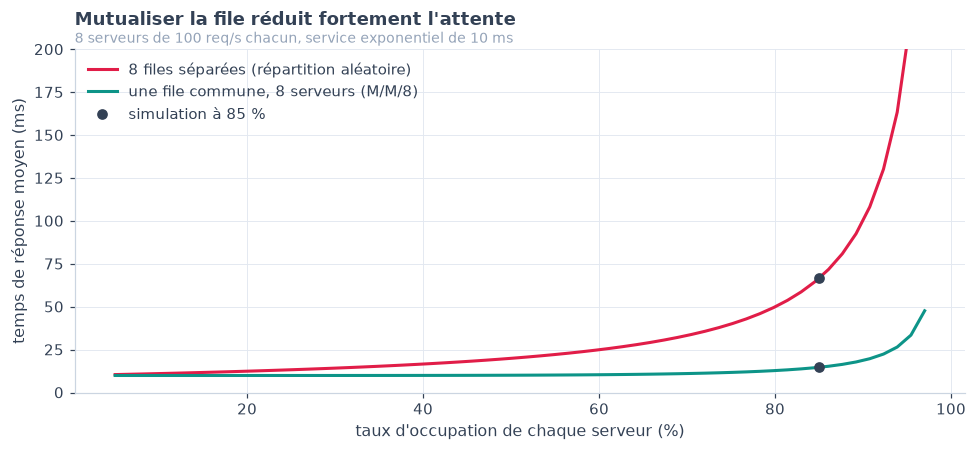

à 85 % : files séparées 67 ms (théorie 67), file commune 14.7 ms (théorie 14.8)


In [7]:
c = 8
rhos_ = np.linspace(0.05, 0.97, 60)
sep = [rq.mm1(r * mu, mu)["W"] * 1e3 for r in rhos_]
com = [rq.mmc(r * c * mu, mu, c)["W"] * 1e3 for r in rhos_]
# simulation de contrôle à 85 % d'occupation
r_chk, n = 0.85, 200_000
arr = rq.poisson_arrivals(r_chk * c * mu, n, seed=11)
svc = np.random.default_rng(12).exponential(1 / mu, n)
st, en = rq.simulate_fifo(arr, svc, c=c)
w_com = (en - arr).mean() * 1e3
dest = np.random.default_rng(13).integers(0, c, n)
w_sep = []
for k in range(c):
    m = dest == k
    st_k, en_k = rq.simulate_fifo(arr[m], svc[m])
    w_sep.append(en_k - arr[m])
w_sep = np.concatenate(w_sep).mean() * 1e3

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(rhos_ * 100, sep, color=ROSE, label=f"{c} files séparées (répartition aléatoire)")
ax.plot(rhos_ * 100, com, color=TEAL, label=f"une file commune, {c} serveurs (M/M/{c})")
ax.plot([r_chk * 100] * 2, [w_sep, w_com], "o", color=SLATE, label="simulation à 85 %")
ax.set_ylim(0, 200); ax.set_xlabel("taux d'occupation de chaque serveur (%)"); ax.set_ylabel("temps de réponse moyen (ms)")
ax.set_title("Mutualiser la file réduit fortement l'attente")
subtitle(ax, f"{c} serveurs de 100 req/s chacun, service exponentiel de 10 ms")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"à 85 % : files séparées {w_sep:.0f} ms (théorie {rq.mm1(0.85 * mu, mu)['W'] * 1e3:.0f}), "
      f"file commune {w_com:.1f} ms (théorie {rq.mmc(0.85 * c * mu, mu, c)['W'] * 1e3:.1f})")

À 85 % d'occupation, la file commune divise le temps de réponse moyen par plus de quatre.
Les grands systèmes s'en rapprochent avec des répartiteurs qui envoient la requête au
serveur le moins chargé, ou à celui des deux choisis au hasard qui a la file la plus
courte.

**Dimensionner.** Un service reçoit 2 000 requêtes par seconde, chacune demande 10 ms
de CPU. Il faut au minimum $a = \lambda/\mu = 20$ cœurs pour suivre ; combien en faut-il
pour que moins de 1 % des requêtes attendent plus de 5 ms ?

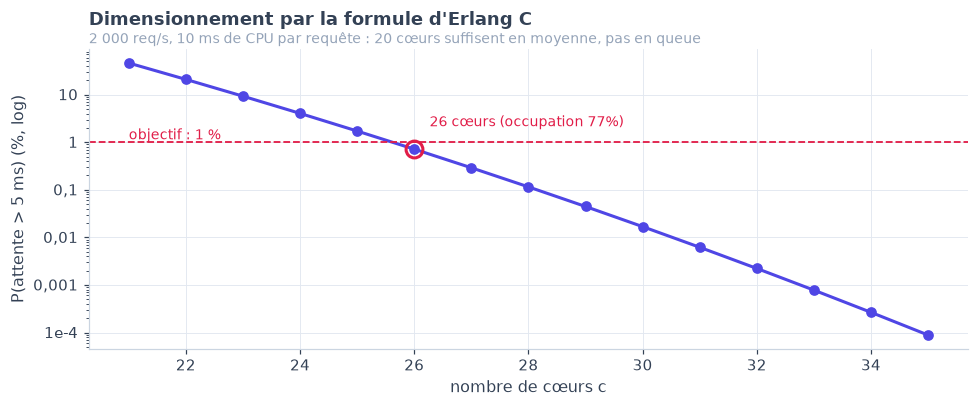

In [8]:
lam_d, t_cible = 2000.0, 0.005
cs = np.arange(21, 36)
p_att = np.array([rq.erlang_c(int(k), lam_d / mu) * math.exp(-(k * mu - lam_d) * t_cible) for k in cs])
c_min = int(cs[np.argmax(p_att < 0.01)])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.semilogy(cs, p_att * 100, "o-", color=INDIGO)
ax.axhline(1, color=ROSE, ls="--", lw=1.2); ax.text(21, 1.15, "objectif : 1 %", color=ROSE, fontsize=9)
ax.plot(c_min, p_att[cs == c_min][0] * 100, "o", color=ROSE, ms=11, mfc="none", mew=2)
ax.annotate(f"{c_min} cœurs (occupation {lam_d / mu / c_min:.0%})", (c_min, p_att[cs == c_min][0] * 100), (10, 15),
            textcoords="offset points", fontsize=9, color=ROSE)
rq.plain_log_axis(ax, "y")
ax.set_xlabel("nombre de cœurs c"); ax.set_ylabel("P(attente > 5 ms) (%, log)")
ax.set_title("Dimensionnement par la formule d'Erlang C")
subtitle(ax, "2 000 req/s, 10 ms de CPU par requête : 20 cœurs suffisent en moyenne, pas en queue")
plt.tight_layout(); plt.show()

Il faut 26 cœurs, soit une occupation d'environ 77 % : la marge de près d'un quart est
le prix d'un objectif sur la queue de distribution. Plus le système est grand, plus
cette marge relative peut être faible (c'est l'**effet d'échelle** des files mutualisées).

> **À retenir.** Une file commune à $c$ serveurs vaut bien mieux que $c$ files séparées.
> Erlang C permet de dimensionner un service pour un objectif d'attente : la capacité
> nécessaire dépasse toujours la charge moyenne.

## 5. Mesurer sous charge : boucle ouverte ou boucle fermée

Pour tester la scalabilité, on génère une charge artificielle. Le piège : si chaque
client **attend la réponse** avant d'envoyer la requête suivante (boucle fermée), alors
un serveur qui ralentit reçoit automatiquement moins de requêtes ; les files restent
artificiellement courtes et la mesure est trop optimiste. Le générateur doit envoyer ses
requêtes **indépendamment** des temps de réponse (boucle ouverte), comme le font de vrais
utilisateurs nombreux et indépendants. Ce biais porte le nom d'**omission coordonnée**
(coordinated omission).

Expérience : un serveur (service exponentiel de 10 ms) fige pendant deux secondes à
t = 50 s (pause du ramasse-miettes, par exemple). On le mesure avec un générateur en
boucle ouverte (Poisson, 50 req/s) puis en boucle fermée (5 clients qui enchaînent
chacun une requête toutes les 100 ms après réception de la réponse, soit le même débit
moyen).

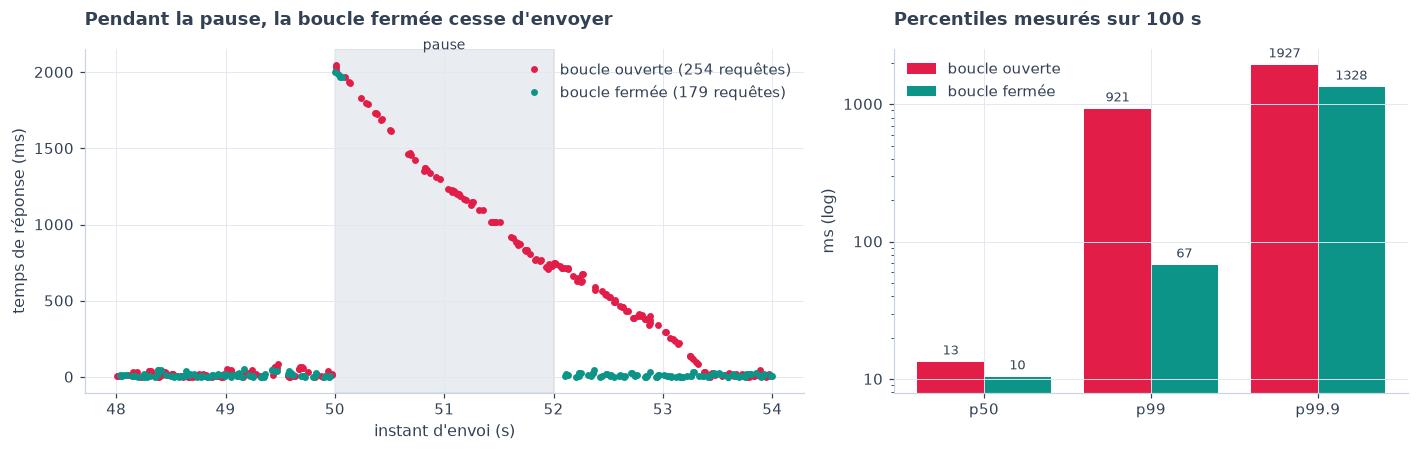

,boucle ouverte,boucle fermée
p50,13.0,10.0
p99,921.0,67.0
p99.9,1927.0,1328.0


In [9]:
PAUSE = (50.0, 52.0)
def serve(t_arr, free, s):
    """Instant de fin d'une requête arrivée à t_arr sur un serveur libre à `free`, avec la pause."""
    start = max(t_arr, free)
    if PAUSE[0] <= start < PAUSE[1]:
        start = PAUSE[1]
    end = start + s
    if start < PAUSE[0] < end:            # la pause interrompt le service en cours
        end += PAUSE[1] - PAUSE[0]
    return end

g = np.random.default_rng(5)
# boucle ouverte
arr = rq.poisson_arrivals(50, 5000, seed=21)
free, ouvert = 0.0, []
for t_ in arr:
    free = serve(t_, free, g.exponential(0.01))
    ouvert.append((t_, free - t_))
ouvert = np.array(ouvert)
# boucle fermée : 5 clients, temps de réflexion 100 ms ; le serveur est FIFO
import heapq
clients = [(k * 0.02, k) for k in range(5)]
heapq.heapify(clients)
free, ferme = 0.0, []
while clients:
    t_, k = heapq.heappop(clients)
    if t_ > arr[-1]:
        continue
    free = serve(t_, free, g.exponential(0.01))
    ferme.append((t_, free - t_))
    heapq.heappush(clients, (free + 0.1, k))
ferme = np.array(ferme)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
for data, color, nom in [(ouvert, ROSE, "boucle ouverte"), (ferme, TEAL, "boucle fermée")]:
    m = (data[:, 0] > 48) & (data[:, 0] < 54)
    ax.plot(data[m, 0], data[m, 1] * 1e3, "o", ms=3.5, color=color, label=f"{nom} ({m.sum()} requêtes)")
ax.axvspan(*PAUSE, color=GRAY, alpha=0.2); ax.text(51, 2150, "pause", ha="center", color=SLATE, fontsize=9)
ax.set_xlabel("instant d'envoi (s)"); ax.set_ylabel("temps de réponse (ms)")
ax.set_title("Pendant la pause, la boucle fermée cesse d'envoyer")
ax.legend(loc="upper right")
qs_ = [50, 99, 99.9]
tab = pd.DataFrame({nom: [np.percentile(d[:, 1] * 1e3, q) for q in qs_] for nom, d in
                    [("boucle ouverte", ouvert), ("boucle fermée", ferme)]}, index=[f"p{q:g}" for q in qs_])
x_ = np.arange(len(qs_))
ax2.bar(x_ - 0.2, tab["boucle ouverte"], width=0.4, color=ROSE, label="boucle ouverte")
ax2.bar(x_ + 0.2, tab["boucle fermée"], width=0.4, color=TEAL, label="boucle fermée")
annotate_bars(ax2, "{:.0f}", fontsize=8.5)
ax2.set_xticks(x_); ax2.set_xticklabels(tab.index); ax2.set_yscale("log"); rq.plain_log_axis(ax2, "y")
ax2.set_ylabel("ms (log)"); ax2.set_title("Percentiles mesurés sur 100 s")
ax2.legend(loc="upper left")
plt.tight_layout(); plt.show()
tab.round(0)

Les deux générateurs mesurent le même serveur, et les médianes sont proches. Mais pendant
la pause, la boucle fermée n'envoie que cinq requêtes (une par client) puis attend : les
deux secondes perdues n'apparaissent que dans cinq mesures sur 5 000, et le p99 reste
bas. En boucle ouverte, une centaine de requêtes arrivent pendant la pause, puis la file
met encore un moment à se vider : le p99 révèle l'incident, et c'est bien ce qu'auraient
vécu de vrais utilisateurs.

> **À retenir.** Un générateur de charge doit envoyer ses requêtes indépendamment des
> réponses (boucle ouverte). En boucle fermée, les ralentissements freinent la charge
> et disparaissent des mesures (omission coordonnée).

## 6. Quand un système surchargé ne se rétablit pas (encadré *When an Overloaded System Won't Recover*)

Près de la saturation, un système peut entrer dans un **cercle vicieux** : la file
s'allonge, les temps de réponse dépassent le délai d'expiration (timeout) des clients,
qui **relancent** leurs requêtes ; la charge augmente encore, la file s'allonge... C'est
une **tempête de relances** (retry storm). Pire, le serveur continue de traiter des
requêtes dont le client est déjà parti : il travaille à plein pour rien. Même quand la
cause initiale disparaît, le système peut rester bloqué dans cet état surchargé jusqu'à
un redémarrage : c'est une **panne métastable** (metastable failure).

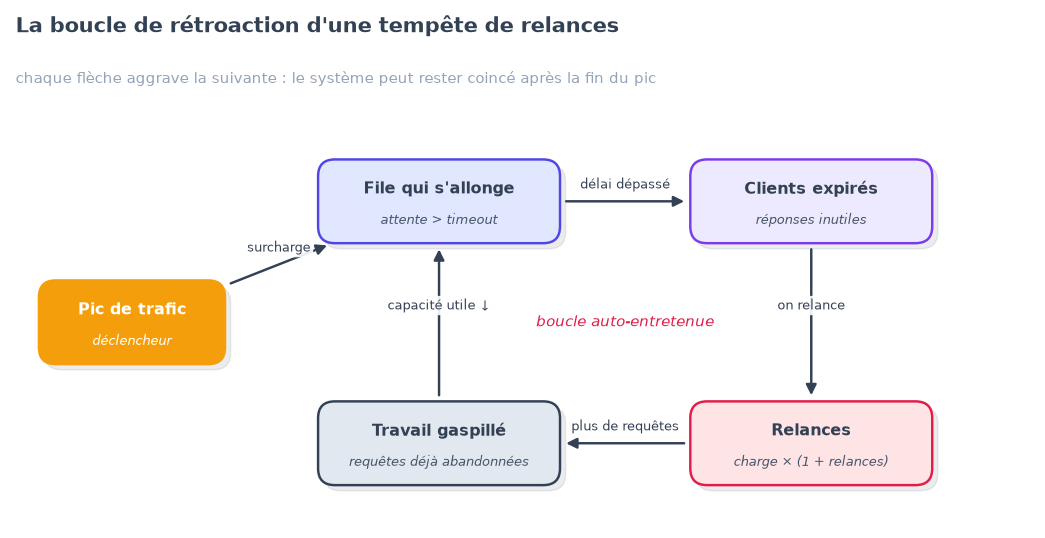

In [10]:
from ddia.overload import RetryPolicy, simulate_overload

d = Diagram(11, 4.6, title="La boucle de rétroaction d'une tempête de relances",
            subtitle="chaque flèche aggrave la suivante : le système peut rester coincé après la fin du pic")
d.box("pic", 1.3, 2.2, "Pic de trafic", sub="déclencheur", color=AMBER, w=2.0, filled=True)
d.box("file", 4.6, 3.5, "File qui s'allonge", sub="attente > timeout", color=INDIGO, w=2.6)
d.box("to", 8.6, 3.5, "Clients expirés", sub="réponses inutiles", color=VIOLET, w=2.6)
d.box("retry", 8.6, 0.9, "Relances", sub="charge × (1 + relances)", color=ROSE, w=2.6)
d.box("travail", 4.6, 0.9, "Travail gaspillé", sub="requêtes déjà abandonnées", color=SLATE, w=2.6)
d.arrow("pic", "file", "surcharge")
d.arrow("file", "to", "délai dépassé")
d.arrow("to", "retry", "on relance")
d.arrow("retry", "travail", "plus de requêtes")
d.arrow("travail", "file", "capacité utile ↓")
d.note(6.6, 2.2, "boucle auto-entretenue", color=ROSE, fontsize=10)
d.show()

Simulons-le (`ddia.overload.simulate_overload`) : un serveur traite 1 000 requêtes par
seconde ; les clients en envoient 800 par seconde (80 % d'occupation), sauf pendant un
pic de 10 secondes à 1 600 par seconde ; ils abandonnent après 1 s. Nous comparons :

1. **sans relance** ;
2. **3 relances immédiates** ;
3. **3 relances avec attente exponentielle et gigue** (exponential backoff with jitter :
   attendre un temps aléatoire entre 0 et 0,2 s, puis 0,4 s, puis 0,8 s) ;
4. **3 relances sous budget** : les relances ne peuvent dépasser 10 % des requêtes
   neuves (à la manière d'un seau à jetons, token bucket) ;
5. **3 relances immédiates, mais délestage côté serveur** (load shedding) : le serveur
   rejette tout de suite, pour un coût minime, une requête qu'il ne pourra pas servir à
   temps.

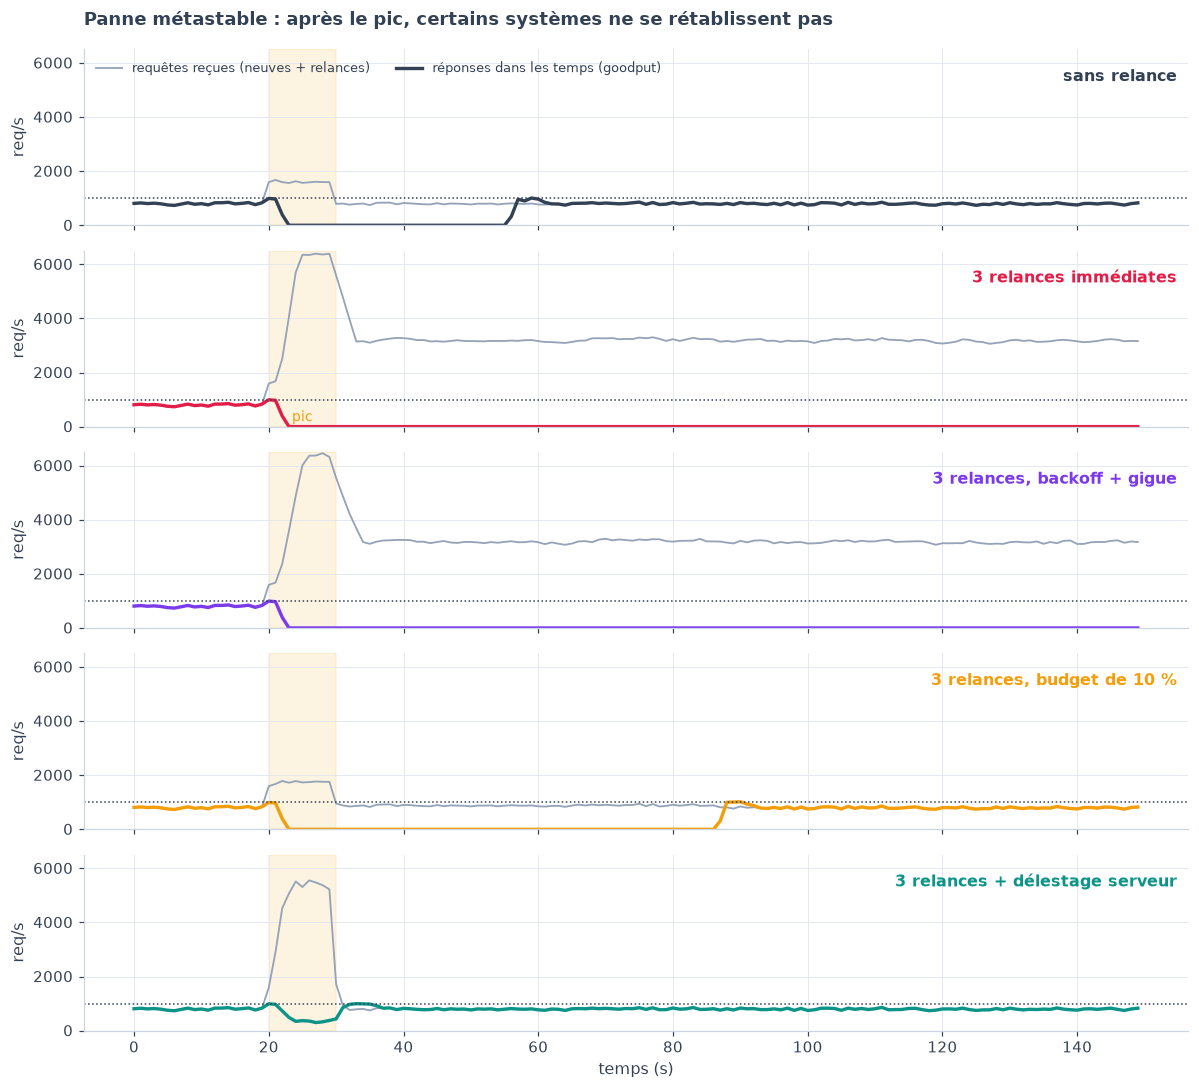

,goodput_final,charge_finale,retour_a_la_normale_s,requetes_gaspillees
sans relance,793.0,793.0,27.0,34047.0
3 relances immédiates,0.0,3172.0,inf,431922.0
"3 relances, backoff + gigue",0.0,3172.0,inf,431076.0
"3 relances, budget de 10 %",793.0,793.0,58.0,64860.0
3 relances + délestage serveur,793.0,793.0,1.0,3407.0


In [11]:
rate_fn = lambda t: 1600.0 if 20 <= t < 30 else 800.0
scenarios = {
    "sans relance": (RetryPolicy(), False),
    "3 relances immédiates": (RetryPolicy(max_retries=3), False),
    "3 relances, backoff + gigue": (RetryPolicy(max_retries=3, backoff=0.2, exponential=True, jitter=True), False),
    "3 relances, budget de 10 %": (RetryPolicy(max_retries=3, budget=0.1), False),
    "3 relances + délestage serveur": (RetryPolicy(max_retries=3), True),
}
runs = {nom: simulate_overload(rate_fn, capacity=1000, duration=150, timeout=1.0, policy=p, shed=sh, seed=3)
        for nom, (p, sh) in scenarios.items()}

fig, axes = plt.subplots(len(runs), 1, figsize=(11, 10), sharex=True)
for ax, (nom, r), col in zip(axes, runs.items(), [SLATE, ROSE, VIOLET, AMBER, TEAL]):
    t = np.arange(r["succes"].size)
    ax.axvspan(20, 30, color=AMBER, alpha=0.12)
    ax.plot(t, r["tentatives"], color=GRAY, lw=1.2, label="requêtes reçues (neuves + relances)")
    ax.plot(t, r["succes"], color=col, lw=2.2, label="réponses dans les temps (goodput)")
    ax.axhline(1000, color=SLATE, ls=":", lw=1)
    ax.set_ylim(0, 6500); ax.set_ylabel("req/s")
    ax.text(0.99, 0.82, nom, transform=ax.transAxes, ha="right", fontsize=10.5, fontweight="bold", color=col)
axes[0].legend(loc="upper left", ncol=2, fontsize=8.5)
axes[1].text(25, 200, "pic", ha="center", color=AMBER, fontsize=9)
axes[-1].set_xlabel("temps (s)")
axes[0].set_title("Panne métastable : après le pic, certains systèmes ne se rétablissent pas")
plt.tight_layout(); plt.show()

recup = {}
for nom, r in runs.items():
    ok = np.where((np.arange(r["succes"].size) > 30) & (r["succes"] > 700))[0]
    recup[nom] = dict(goodput_final=r["succes"][100:150].mean(), charge_finale=r["tentatives"][100:150].mean(),
                      retour_a_la_normale_s=(ok[0] - 30) if ok.size else np.inf,
                      requetes_gaspillees=r["gaspille"].sum())
pd.DataFrame(recup).T.round(0)

Lecture des cinq scénarios :

- **sans relance**, le système se rétablit, mais lentement : le pic a laissé environ
  6 000 requêtes en file, que le serveur écoule à 200 par seconde de marge ; pendant
  ces 30 secondes, toutes les réponses arrivent trop tard (goodput nul) alors que le
  serveur tourne à plein : c'est du **travail gaspillé** ;
- avec **relances immédiates**, la charge reçue grimpe à 3 200 requêtes par seconde
  (chaque requête neuve devient quatre tentatives, toutes expirées) et **ne redescend
  jamais** : le pic a fait basculer le système dans un second état stable, où il ne
  produit plus rien. C'est la panne métastable ;
- l'**attente exponentielle avec gigue** ne suffit pas ici : elle étale les relances
  dans le temps mais n'en réduit pas le nombre, et chaque tentative expire encore. Elle
  est utile contre les rafales synchronisées (tous les clients relançant au même
  instant), pas contre une surcharge durable ;
- le **budget de relances** borne la charge à 110 % du trafic neuf : le système met
  deux fois plus longtemps que sans relance à écouler sa file, mais il se rétablit ;
- le **délestage** côté serveur est le plus efficace : les requêtes rejetées coûtent
  presque rien, la file reste sous le timeout, et les requêtes acceptées sont servies à
  temps. Le goodput baisse pendant le pic (les relances immédiates des requêtes rejetées
  occupent encore un peu le serveur), mais il n'y a presque pas de travail gaspillé et
  le retour à la normale est immédiat.

Le livre cite aussi les **disjoncteurs** (circuit breakers : un client cesse
temporairement d'appeler un service qui a récemment échoué) et la **contre-pression**
(backpressure : le serveur demande aux clients de ralentir). Tous partagent la même
idée : couper la boucle de rétroaction.

> **À retenir.** Relancer aveuglément transforme une surcharge passagère en panne
> durable (métastable). On borne les relances (budget, disjoncteur), on les étale
> (backoff avec gigue) et, côté serveur, on rejette tôt ce qu'on ne pourra pas servir à
> temps (délestage, contre-pression).

## Synthèse

- Le temps de réponse d'une file croît comme $1/(1-\rho)$ : il **explose** quand le débit
  approche de la capacité, d'où la nécessité d'une marge.
- L'attente vient du **hasard** des arrivées et de la **variabilité** des services
  (Pollaczek-Khinchine) ; quelques requêtes lentes bloquent les rapides (**blocage en
  tête de file**).
- La **loi de Little** $L = \lambda W$ relie débit, latence et requêtes en cours.
- Une **file commune** à plusieurs serveurs vaut mieux que des files séparées ; Erlang C
  permet de **dimensionner** pour un objectif de queue.
- On mesure avec un générateur en **boucle ouverte**, sinon les ralentissements
  disparaissent des mesures.
- Les **relances** non maîtrisées peuvent rendre une surcharge **métastable** ; on les borne et on déleste.

Le cours 4 passe à la deuxième exigence du chapitre : la **fiabilité**. Les délais réseau
et les files d'attente des commutateurs reviennent au chapitre 9.